# 04 · Companies written by an LLM

**The question this step answers:** rule-based names are standard names with noise on top. Real bookkeepers use their *own* words: "Gross wages shop staff", "Huur kantoor Gent", "Acompte logiciel planning chantiers". To get names like that, an LLM (Claude Opus) plays the bookkeeper of a small Belgian company and writes its chart of accounts. One call per company, 78 companies in total. Each answer is saved ("frozen") once and never asked again.

**Where it sits in the pipeline:** next to the rule-based companies (notebook 03). One third of all accounts come from here, and they are the hard ones.

**The code:** `src/d1/datagen/llm_charts.py`: `build_prompt` → `fetch_llm_company` (one call, writes the frozen file) → `load_llm_company` (frozen file → accounts). The prompt is in `prompts/generate_company_chart.md`.

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

import glob
from rapidfuzz import fuzz

from d1.datagen.llm_charts import build_prompt, load_llm_company, parse_chart
from d1.datagen.schema import read_jsonl
from d1.datagen.splits import normalize_name

frozen = {}
for path in sorted(glob.glob(str(config.data.frozen_llm_dir / "*.json"))):
    record = json.loads(open(path, encoding="utf-8").read())
    frozen[record["company_id"]] = record
print(f"{len(frozen)} frozen LLM companies")

78 frozen LLM companies


## 1. The company we follow

One dev company: a construction company that writes in Dutch and French (*mixed*).

In [2]:
cid = next(c for c, r in frozen.items() if r["split"] == "dev" and r["industry"] == "construction" and r["language"] == "mixed")
record = frozen[cid]
display(pd.Series({k: v for k, v in record.items() if k not in ("response", "group_codes", "usage")} | record["usage"], name=cid).to_frame())

,dev-c041
company_id,dev-c041
split,dev
industry,construction
language,mixed
requested_model,claude-opus-5-5
served_model,claude-opus-5-5
backend,ClaudeCLIBackend
prompt_version,v1
prompt_sha256,8c3df7673398d70366edfcad77381deda871b88d688cf5f16f77e09f18a4ab24
n_accounts,50


## 2. What happens, step by step

1. **Choose the groups.** As for a rule-based company, 80% of the accounts get a different standard group, drawn at random. *We* choose the groups, not the LLM, so every group appears and the answer key is known.
2. **Build the prompt:** the bookkeeper role, the industry, the language, the number of accounts, and a table of the chosen groups with their official names. It says explicitly: *do not copy the standard names, write them the way your company would*.
3. **One call to the generator model** (Claude Opus, through the Claude CLI on your own login). The answer must follow a JSON schema: for every account, `target_code`, `code` and `name`.
4. **Freeze it:** the answer is saved with everything needed to trace it (model, prompt version, prompt fingerprint, cost, time) in `data/frozen/llm_charts/<company>.json`, committed to the repo. Rebuilding the data never calls the LLM again.
5. **Load it** (`load_llm_company`). Drop unusable rows (a group that wasn't given, an empty name, a repeated code), cut to the requested number of accounts, and for *legacy* companies replace the LLM's codes with an unrelated old numbering (notebook 03).

The prompt as it is now (the table is cut after 6 groups here). This company received version v1, which did not yet have the rule against real names; see section 3b:

In [3]:
groups = [by_code[c] for c in record["group_codes"]]
prompt = build_prompt(record["industry"], record["language"], groups, record["n_accounts"])
lines = prompt.splitlines()
table_start = next(i for i, l in enumerate(lines) if l.startswith("|---"))
print("\n".join(lines[: table_start + 7] + ["| ... |", ""] + lines[-1:]))

You are the bookkeeper of a small Belgian construction company. Your accounting software has its own chart of accounts, and you are exporting it.

Below are the 40 groups of the Belgian standard chart (PCMN) that your company uses. Write the accounts your company has for these groups, exactly as they appear in your own system.

Rules:
- Write exactly 50 accounts in total: one for every group, plus a second account for some groups, the way companies split an account by site, project, bank, VAT rate or counterparty.
- Write the account names in a mix of Dutch, French and English, as in a bilingual Brussels company.
- Name the accounts the way a real construction company would in its own system: its own wording, abbreviations, site names and habits. Do not copy the standard names below; they are only there to tell you what each group means.
- Never use the name of a real or invented company, bank, brand, product or person. Where a real system would name one, write a generic word instead, 

## 3. What came back

The first accounts of the answer, next to the official name of the group the LLM says each account belongs to:

In [4]:
answer = pd.DataFrame(record["response"]["accounts"])
answer["official name (en)"] = answer["target_code"].map(lambda c: by_code[c].name_en)
display(answer.head(15))

,target_code,code,name,official name (en)
0,121,121000,Herwaardering gebouw depot Vilvoorde,Revaluation Surpluses on Tangible Fixed Assets
1,122,122000,Plus-value réévaluation particip.,Revaluation Surpluses on Financial Fixed Assets
2,171,171000,Obligatielening 2023-2030 (niet achtergesteld),Unsubordinated Debentures (> 1 Year)
3,176,176000,Acomptes reçus LT - projet Résidence Iris,Advance Payments on Contract in Progress (> 1 Year)
4,210,210000,R&D prefab wandelementen,Research and Development Costs
5,212,212000,Goodwill overname dakwerkbedrijf,Goodwill
6,251,251100,Leasing torenkraan,"Plant, Machinery and Equipment in Leasing or Other Similar Rights"
7,251,251200,Leasing graafmachine,"Plant, Machinery and Equipment in Leasing or Other Similar Rights"
8,320,320100,WIP werf Anderlecht - Rue Wayez,Work in Progress - Acquisition Value
9,320,320200,En-cours chantier Uccle - Av. Brugmann,Work in Progress - Acquisition Value


This is the difference with notebook 03. "WIP werf Anderlecht - Rue Wayez" (work in progress on a building site) shares almost no words with its official name, *Work in Progress - Acquisition Value*. A mapper has to *understand* it, not just recognise distorted words.

### 3b. Names cleaned after the fact

The first version of the prompt (v1) asked for names "the way a real company would", and Opus did exactly that: banks, software suppliers, utilities, vehicle brands, invented subsidiaries and a few surnames. A public project shouldn't carry real organisations, so on 2026-11-06 every such name was removed or replaced by a generic word, in all 78 frozen files:

- **Removed** where the rest of the name already says what the account is: a term deposit named after its bank becomes "Term deposit 6m", a leased crane named after its maker becomes "Leasing torenkraan".
- **Replaced by a role** where the name was the point: a loan to a named company becomes "Loan to associate", a goodwill on a named roofing firm becomes "Goodwill overname dakwerkbedrijf".
- **Numbered** where two accounts of one company ended up with the same name ("Current account", "Current account 2"), as a ledger would.

668 of the 3,703 frozen names changed. The group codes, account codes and everything else are as the model wrote them, and each file records the cleanup under `names_scrubbed`. The prompt is now v2, which asks for generic words from the start, so a newly written company would not need the cleanup. `tests/test_no_real_names.py` keeps the names out of the data and the repo; it stores only hashes of the banned names.

The cleanup makes the LLM-written names a little more generic, so a few more test names now also occur in dev (58 of 200 instead of 49, notebook 05).

## 4. From frozen file to accounts

`load_llm_company` turns the answer into the company's accounts. Asked for exactly 50, the LLM sometimes writes 49 or 51, and `parse_chart` drops unusable rows. Across all 78 companies:

In [5]:
asked, written, usable = [], [], []
for c, r in frozen.items():
    rows = parse_chart(r["response"], set(r["group_codes"]))
    asked.append(r["n_accounts"]); written.append(len(r["response"]["accounts"])); usable.append(len(rows))
delivery = pd.DataFrame({"asked": asked, "written": written, "usable": usable})
delivery["difference"] = delivery["written"] - delivery["asked"]
print(delivery["difference"].value_counts().sort_index().rename("companies").rename_axis("written minus asked").to_string())
print(f"\nrows dropped as unusable: {int((delivery['written'] - delivery['usable']).sum())} of {int(delivery['written'].sum())}")

written minus asked
-1     1
 0    73
 1     4

rows dropped as unusable: 0 of 3703


When the LLM writes too many, `_cut_to` drops surplus *second* accounts first, so no group loses its only account. A plain cut at the end would always drop the last groups (class 7, revenue), because the LLM writes in group order.

## 5. How different are LLM names from the official names?

For every dev account: how similar is the name to its group's official name (fuzzy string similarity, 0 = nothing in common, 100 = the same, after removing case, accents and punctuation)? Rule-based names cluster near the top. LLM names spread far lower. This one chart explains why LLM-written accounts are the hard part of the whole project (71.9% on the shortlist against 99.2%, notebook 08).

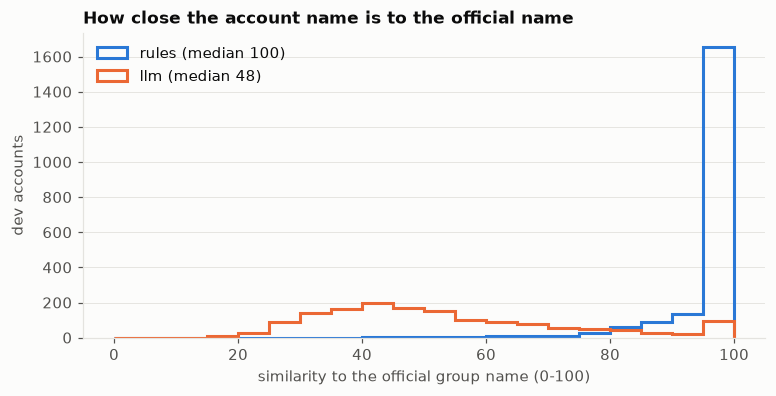

In [6]:
dev = read_jsonl(config.data.generated_dir / "dev.jsonl")
def official(r):
    a = by_code[r.target_code]
    langs = ["nl", "fr", "en"] if r.language == "mixed" else [r.language]
    return max(fuzz.token_set_ratio(normalize_name(r.name), normalize_name(a.name(l))) for l in langs)
sim = pd.DataFrame([{"source": r.source, "similarity": official(r)} for r in dev])
fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(0, 105, 5)
for source in ["rules", "llm"]:
    ax.hist(sim.loc[sim["source"] == source, "similarity"], bins=bins, histtype="step", linewidth=2,
            color=SOURCE_COLORS[source], label=f"{source} (median {sim.loc[sim['source'] == source, 'similarity'].median():.0f})")
ax.set_xlabel("similarity to the official group name (0-100)")
ax.set_ylabel("dev accounts")
ax.grid(axis="x", visible=False)
ax.set_title("How close the account name is to the official name")
ax.legend(loc="upper left")
plt.show()

## 6. The same group, written by different companies

Group 620 (*Remuneration and Direct Social Benefits*, in plain words: wages), as every LLM company in dev wrote it. Staff pay is written "brutolonen", "salaires" or "wages". Only the manager's pay gets the official word (*bezoldiging*, *rémunération*). That is why notebook 08 finds this group hard to retrieve: the official name, the text the embeddings compare with, says *remuneration*.

In [7]:
same_group = [r for r in dev if r.source == "llm" and r.target_code == "620"]
display(pd.DataFrame([{"company": r.company_id, "industry": r.industry, "language": r.language, "name": r.name} for r in same_group]).head(14))

,company,industry,language,name
0,dev-c042,retail,nl,Brutolonen bedienden
1,dev-c042,retail,nl,Bezoldiging zaakvoerder
2,dev-c043,services,fr,Salaires bruts employés
3,dev-c043,services,fr,Rémun. administrateur-gérant
4,dev-c044,software,mixed,Brutolonen bedienden
5,dev-c044,software,mixed,Bonus & cheques-repas devs
6,dev-c050,retail,en,Gross wages shop staff
7,dev-c050,retail,en,Gross salaries office staff
8,dev-c058,retail,nl,Brutolonen bedienden winkel
9,dev-c058,retail,nl,Brutolonen studenten/flexijobs


## 7. Cost and time

All 78 calls were made once, through the Claude CLI on a personal login:

total cost $4.70, median 18 s per company, served models: ['claude-opus-5-5']


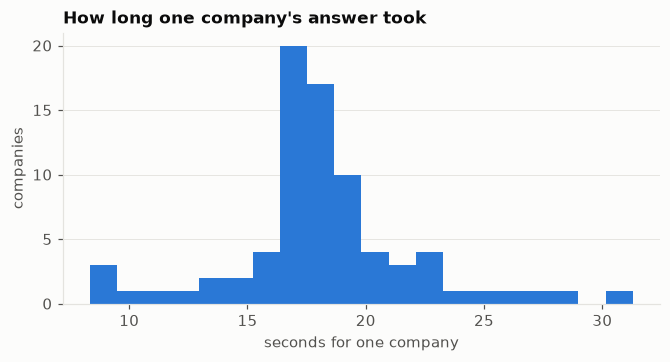

,companies,cost_usd
split,,
dev,30,1.91
test,8,0.27
train,40,2.52


In [8]:
usage = pd.DataFrame([r["usage"] | {"split": r["split"], "served_model": r["served_model"]} for r in frozen.values()])
print(f"total cost ${usage['cost_usd'].sum():.2f}, median {usage['latency_ms'].median() / 1000:.0f} s per company, "
      f"served models: {usage['served_model'].unique().tolist()}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(usage["latency_ms"] / 1000, bins=20, color=SINGLE)
ax.set_xlabel("seconds for one company")
ax.set_ylabel("companies")
ax.grid(axis="x", visible=False)
ax.set_title("How long one company's answer took")
plt.show()
display(usage.groupby("split").agg(companies=("cost_usd", "size"), cost_usd=("cost_usd", "sum")).round(2))

## 8. What is *not* happening

- **The LLM does not pick the groups.** We give it the groups, so the answer key comes from us. What the LLM adds is the *wording*.
- **Its labels are not checked here.** The LLM says which group each account belongs to, and sometimes it is wrong. The hand check of the test split (notebook 06) found 13% of its labels wrong. Train and dev keep the LLM's own labels, which makes LLM-written dev numbers a bit pessimistic for every method alike.
- **The mapper is never tested on its own writing.** The generator (Opus) and the mapping LLM (Haiku) are different models, and the config refuses to load if they are the same.